## Interval Analysis

In [3]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = False
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 200)
        self.fc2 = nn.Linear(200,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = self.fc2(x)
        x = F.softmax(x, dim=-1) # added softmax for probabilities
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()


100.0%
100.0%
100.0%
100.0%


Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=200, bias=True)
    (fc2): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [4]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        print(f'Accuracy on images: {100 * correct / total}')

In [5]:
train_model(model, 15)
test_model(model)

Epoch 1/15, Loss: 2.012
Epoch 2/15, Loss: 1.729
Epoch 3/15, Loss: 1.627
Epoch 4/15, Loss: 1.596
Epoch 5/15, Loss: 1.582
Epoch 6/15, Loss: 1.572
Epoch 7/15, Loss: 1.566
Epoch 8/15, Loss: 1.561
Epoch 9/15, Loss: 1.557
Epoch 10/15, Loss: 1.553
Epoch 11/15, Loss: 1.550
Epoch 12/15, Loss: 1.547
Epoch 13/15, Loss: 1.545
Epoch 14/15, Loss: 1.542
Epoch 15/15, Loss: 1.540
Accuracy on images: 93.43


### Write the interval analysis for the simple model

In [ ]:
## TODO: Write the interval analysis for the simple model
## you can use https://github.com/Zinoex/bound_propagation

# finidng the lower and upper bounds of the first layer given the input image and epsilon

def interval_bounds(model, input_image, epsilon):
    net = model[1]

    # Get the lower and upper bounds of the input image
    lower_bound = torch.clamp(input_image - epsilon, 0, 1)
    upper_bound = torch.clamp(input_image + epsilon, 0, 1)

    lower_bound = (lower_bound - 0.1307) / 0.3081
    upper_bound = (upper_bound - 0.1307) / 0.3081

    lower_bound = lower_bound.view(input_image.size(0), -1)
    upper_bound = upper_bound.view(input_image.size(0), -1)

    # Get the weights and biases of the first layer
    W1 = net.fc.weight.data
    b1 = net.fc.bias.data

    W1_pos = torch.clamp(W1, min=0)
    W1_neg = torch.clamp(W1, max=0)

    # Compute the lower and upper bounds of the first layer
    z1_lower = F.linear(lower_bound, W1_pos) + F.linear(upper_bound, W1_neg) + b1
    z1_upper = F.linear(upper_bound, W1_pos) + F.linear(lower_bound, W1_neg) + b1

    # Apply ReLU activation
    z1_lower = F.relu(z1_lower)
    z1_upper = F.relu(z1_upper)

    return z1_lower, z1_upper

# Verify the model's robustness for a given epsilon

def verify (model, images, Labels, epsilon):
    net = model[1]
    z1_lower, z1_upper = interval_bounds(model, images, epsilon)

    # Get the weights and biases of the second layer
    W2 = net.fc2.weight.data
    b2 = net.fc2.bias.data

    W2_y = W2[Labels]
    b2_y = b2[Labels]

    diff_W2 = W2_y.unsqueeze(1) - W2.unsqueeze(0)
    diff_b2 = b2_y.unsqueeze(1) - b2.unsqueeze(0)

    diff_W2_pos = torch.clamp(diff_W2, min=0)
    diff_W2_neg = torch.clamp(diff_W2, max=0)

    lower_diff = (torch.sum(diff_W2_pos * z1_lower.unsqueeze(1) + diff_W2_neg * z1_upper.unsqueeze(1), dim=2) + diff_b2)

    verified = (lower_diff >= -1e-7).all(dim=1)

    return verified

# Evaluate the model's clean and verified accuracy for a given epsilon

def evaluate_verification(model, test_loader, epsilon):
    model.eval()
    clean_count = 0
    verified_count = 0
    total_count = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            predictions = torch.argmax(outputs, dim=1)

            clean_count += (predictions == labels).sum().item()
            total_count += labels.size(0)

            verified = verify(model, images, labels, epsilon)
            verified_count += (verified & (predictions == labels)).sum().item()

    clean_accuracy = 100 * clean_count / total_count
    verified_accuracy = 100 * verified_count / total_count

    return clean_accuracy, verified_accuracy

In [ ]:
# trying to find the best epsilon for which the model is still robust. 
# We will evaluate the model for different values of epsilon and report the clean accuracy, verified accuracy, and time taken for each evaluation.

epsilon = np.linspace(0.01, 0.1, 10)

results = []

model.eval()

for eps in epsilon:
    start_time = time.time()
    clean_acc, verified_acc = evaluate_verification(model, test_loader, float(eps))
    elapsed_time = time.time() - start_time
    results.append((eps, clean_acc, verified_acc, elapsed_time))
    print(f"Epsilon: {eps:.3f}, Clean Accuracy: {clean_acc:.2f}%, Verified Accuracy: {verified_acc:.2f}%, Time: {elapsed_time:.2f}s")

Epsilon: 0.010, Clean Accuracy: 93.43%, Verified Accuracy: 70.55%, Time: 0.77s
Epsilon: 0.020, Clean Accuracy: 93.43%, Verified Accuracy: 23.68%, Time: 0.74s
Epsilon: 0.030, Clean Accuracy: 93.43%, Verified Accuracy: 4.56%, Time: 0.78s
Epsilon: 0.040, Clean Accuracy: 93.43%, Verified Accuracy: 0.58%, Time: 0.79s
Epsilon: 0.050, Clean Accuracy: 93.43%, Verified Accuracy: 0.02%, Time: 0.79s
Epsilon: 0.060, Clean Accuracy: 93.43%, Verified Accuracy: 0.00%, Time: 0.75s
Epsilon: 0.070, Clean Accuracy: 93.43%, Verified Accuracy: 0.00%, Time: 0.78s
Epsilon: 0.080, Clean Accuracy: 93.43%, Verified Accuracy: 0.00%, Time: 0.78s
Epsilon: 0.090, Clean Accuracy: 93.43%, Verified Accuracy: 0.00%, Time: 0.81s
Epsilon: 0.100, Clean Accuracy: 93.43%, Verified Accuracy: 0.00%, Time: 1.24s


,Epsilon,Clean Accuracy,Verified Accuracy,Time
0,0.01,93.43,70.55,0.7657
1,0.02,93.43,23.68,0.7401
2,0.03,93.43,4.56,0.7761
3,0.04,93.43,0.58,0.7929
4,0.05,93.43,0.02,0.7887
5,0.06,93.43,0.00,0.7541
6,0.07,93.43,0.00,0.7835
7,0.08,93.43,0.00,0.7767
8,0.09,93.43,0.00,0.8074
9,0.10,93.43,0.00,1.2401


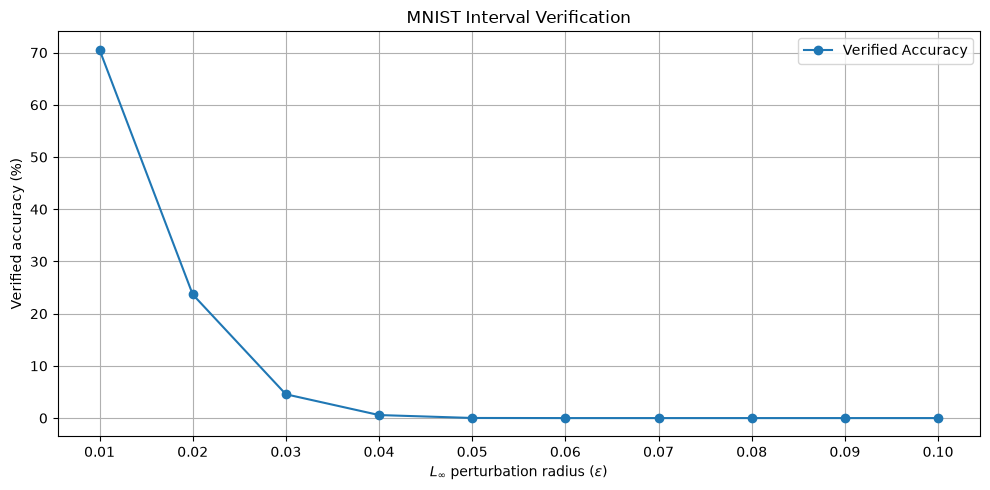

In [ ]:
import pandas as pd

# Creating a DataFrame to display the results

results_df = pd.DataFrame(results, columns=['Epsilon', 'Clean Accuracy', 'Verified Accuracy', 'Time'])

display(results_df.round(4))

plt.figure(figsize=(10, 5))
plt.plot(results_df['Epsilon'], results_df['Verified Accuracy'], label='Verified Accuracy', marker='o')
plt.xlabel(r"$L_\infty$ perturbation radius ($\epsilon$)")
plt.ylabel("Verified accuracy (%)")
plt.title("MNIST Interval Verification")
plt.xticks(epsilon.round(2))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()